In [8]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

# Ensure plots directory exists
os.makedirs("plots", exist_ok=True)


In [11]:
dataset = pd.read_csv("https://raw.githubusercontent.com/mrdbourke/zero-to-mastery-ml/refs/heads/master/data/heart-disease.csv")
dataset.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB

=== Missing Values ===
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal  

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000



=== Target Distribution (1 = Disease, 0 = No Disease) ===
target
1    165
0    138
Name: count, dtype: int64


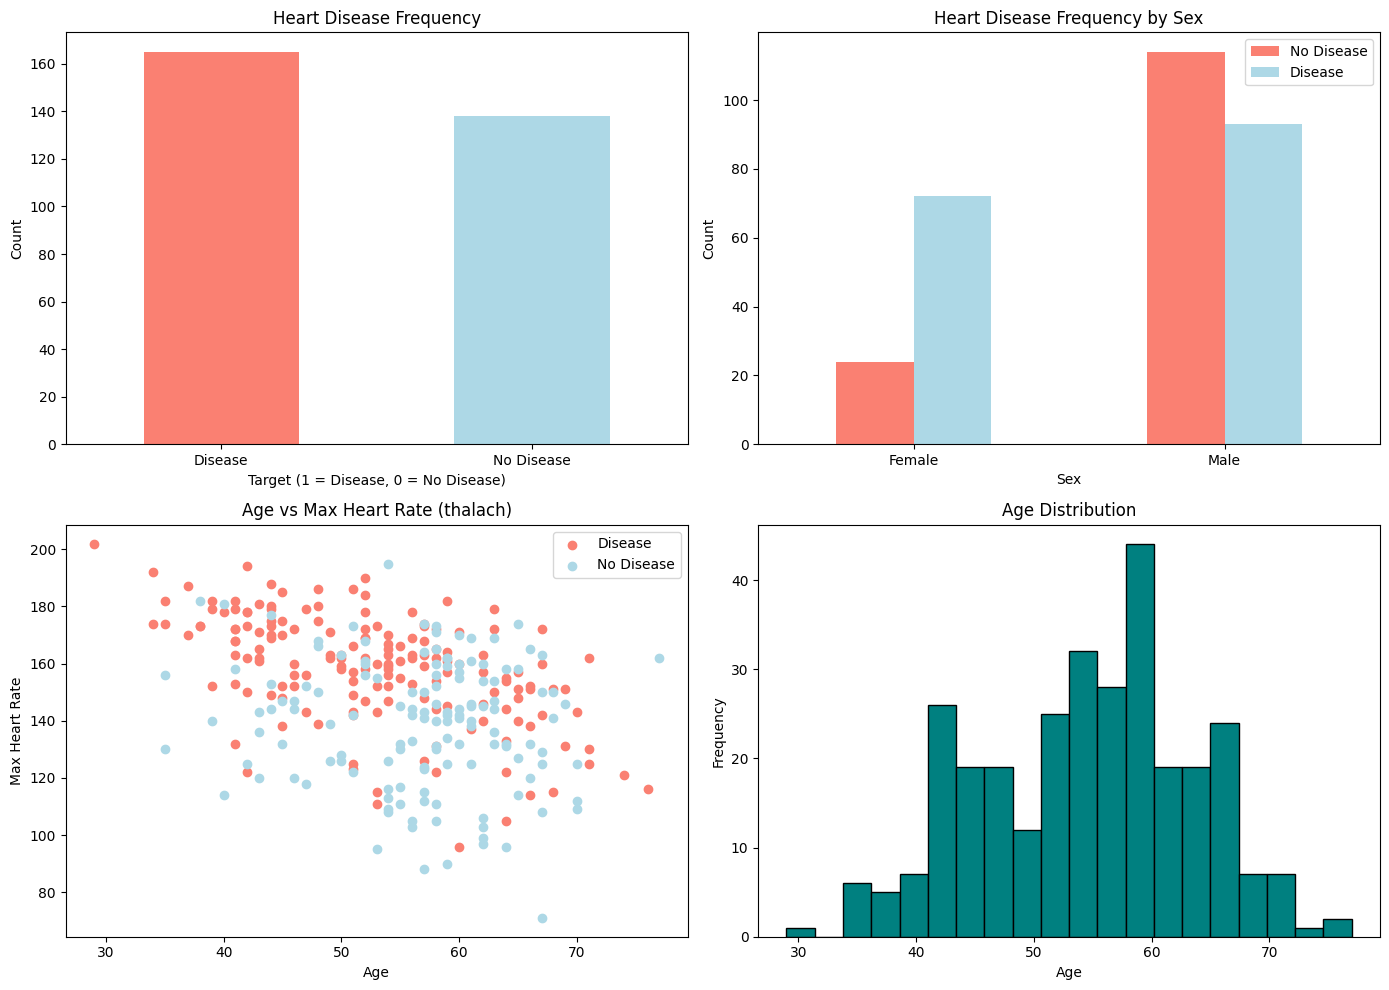

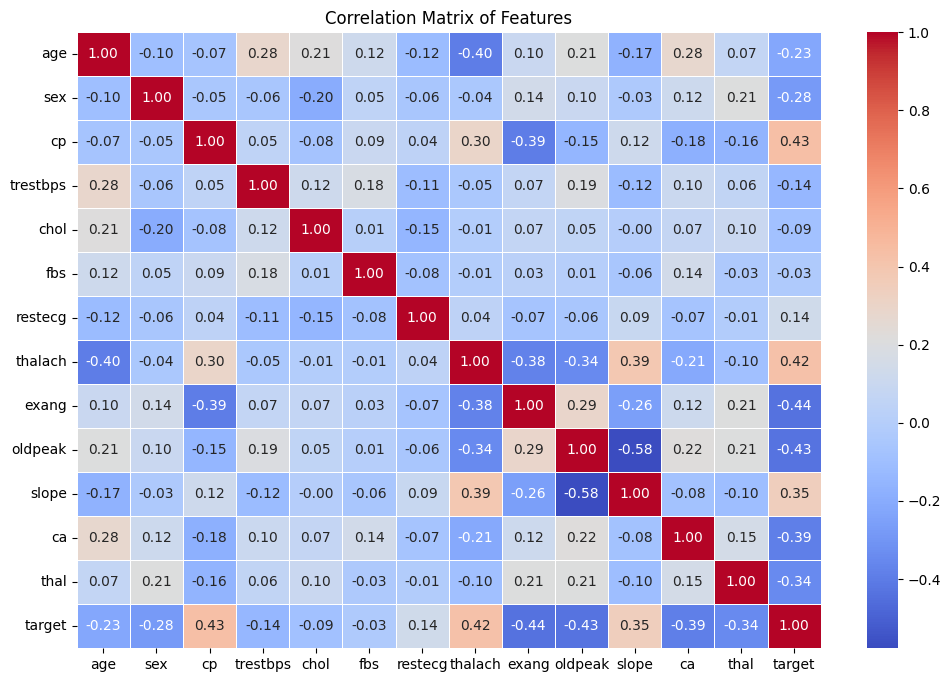

In [12]:
import seaborn as sns

# 1. Basic Structure & Missing Values Check
print("=== Dataset Info ===")
dataset.info()

print("\n=== Missing Values ===")
print(dataset.isna().sum())

print("\n=== Summary Statistics ===")
display(dataset.describe())

print("\n=== Target Distribution (1 = Disease, 0 = No Disease) ===")
print(dataset["target"].value_counts())

# 2. Visualizations Overview
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Target distribution
dataset["target"].value_counts().plot(kind="bar", color=["salmon", "lightblue"], ax=axes[0, 0])
axes[0, 0].set_title("Heart Disease Frequency")
axes[0, 0].set_xlabel("Target (1 = Disease, 0 = No Disease)")
axes[0, 0].set_ylabel("Count")
axes[0, 0].set_xticklabels(["Disease", "No Disease"], rotation=0)

# Target frequency by sex (0 = Female, 1 = Male)
pd.crosstab(dataset["sex"], dataset["target"]).plot(kind="bar", color=["salmon", "lightblue"], ax=axes[0, 1])
axes[0, 1].set_title("Heart Disease Frequency by Sex")
axes[0, 1].set_xlabel("Sex")
axes[0, 1].set_ylabel("Count")
axes[0, 1].legend(["No Disease", "Disease"])
axes[0, 1].set_xticklabels(["Female", "Male"], rotation=0)

# Age vs Max Heart Rate (thalach)
axes[1, 0].scatter(dataset.age[dataset.target == 1], dataset.thalach[dataset.target == 1], c="salmon", label="Disease")
axes[1, 0].scatter(dataset.age[dataset.target == 0], dataset.thalach[dataset.target == 0], c="lightblue", label="No Disease")
axes[1, 0].set_title("Age vs Max Heart Rate (thalach)")
axes[1, 0].set_xlabel("Age")
axes[1, 0].set_ylabel("Max Heart Rate")
axes[1, 0].legend()

# Age distribution
dataset["age"].plot(kind="hist", bins=20, ax=axes[1, 1], color="teal", edgecolor="black")
axes[1, 1].set_title("Age Distribution")
axes[1, 1].set_xlabel("Age")

plt.tight_layout()
os.makedirs("plots", exist_ok=True)
plt.savefig("plots/visualizations_overview.png", bbox_inches="tight")
plt.show()

# 3. Correlation Matrix Heatmap
plt.figure(figsize=(12, 8))
corr_matrix = dataset.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Matrix of Features")
os.makedirs("plots", exist_ok=True)
plt.savefig("plots/correlation_matrix_heatmap.png", bbox_inches="tight")
plt.show()

In [13]:
dataset.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [14]:
dataset['sex'].value_counts()

,count
sex,
1,207
0,96


In [15]:
pd.crosstab(dataset['sex'], dataset['target'])

target,0,1
sex,,
0,24,72
1,114,93


### Chest Pain Type vs. Target Variable

**Chest pain types (`cp`):**
- **0: Typical Angina** — chest pain related to decreased blood supply to the heart
- **1: Atypical Angina** — chest pain not related to heart
- **2: Non-anginal pain** — typically esophageal spasms (non heart-related)
- **3: Asymptomatic** — chest pain not showing signs of disease

In [16]:
# Compare chest pain type with target variable
pd.crosstab(dataset["cp"], dataset["target"])

target,0,1
cp,,
0,104,39
1,9,41
2,18,69
3,7,16


FileNotFoundError: [Errno 2] No such file or directory: 'plots/05_chest_pain_vs_target.png'

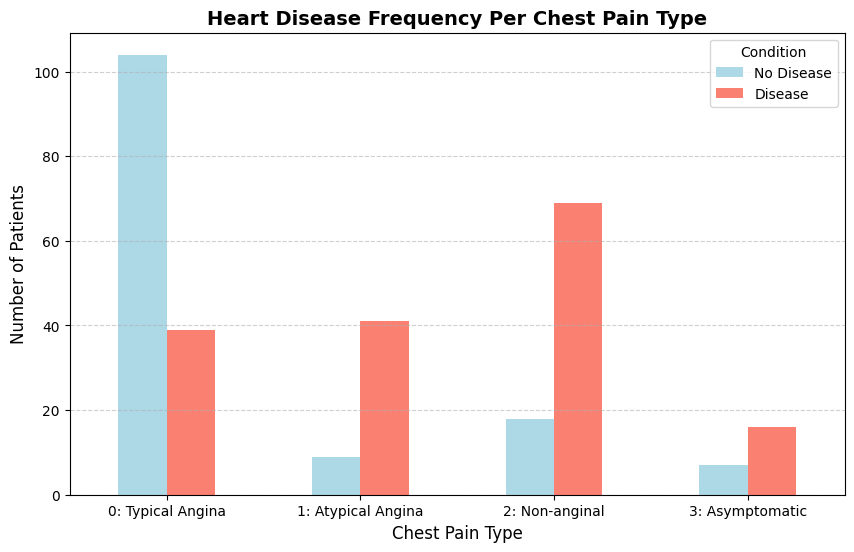

In [17]:
# Visualize the relationship between chest pain types and target
pd.crosstab(dataset["cp"], dataset["target"]).plot(
    kind="bar",
    figsize=(10, 6),
    color=["lightblue", "salmon"]
)

# Add title and labels
plt.title("Heart Disease Frequency Per Chest Pain Type", fontsize=14, fontweight="bold")
plt.xlabel("Chest Pain Type", fontsize=12)
plt.ylabel("Number of Patients", fontsize=12)
plt.legend(["No Disease", "Disease"], title="Condition")
plt.xticks(
    ticks=[0, 1, 2, 3],
    labels=["0: Typical Angina", "1: Atypical Angina", "2: Non-anginal", "3: Asymptomatic"],
    rotation=0
)
plt.grid(axis="y", linestyle="--", alpha=0.6)
os.makedirs("plots", exist_ok=True)
plt.savefig("plots/05_chest_pain_vs_target.png", bbox_inches="tight")
plt.show()

# 5. Modeling

## 5. Modeling

We have explored our dataset. Now we will train machine learning models to predict heart disease (`target`) using the 13 clinical attributes.

We will evaluate 3 baseline classification algorithms:
1. **Logistic Regression**
2. **K-Nearest Neighbors (`KNeighborsClassifier`)**
3. **Random Forest Classifier (`RandomForestClassifier`)**

In [18]:
# Split data into features (X) and target (y)
X = dataset.drop("target", axis=1)
y = dataset["target"]

# Split data into train and test sets (80% train, 20% test)
from sklearn.model_selection import train_test_split

np.random.seed(42)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (242, 13)
X_test shape: (61, 13)


In [19]:
# Import models from Scikit-Learn
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Put models in a dictionary
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier()
}

# Function to fit and score models
def fit_and_score(models, X_train, X_test, y_train, y_test):
    """
    Fits and evaluates given Scikit-Learn machine learning models.
    """
    np.random.seed(42)
    model_scores = {}
    for name, model in models.items():
        model.fit(X_train, y_train)
        model_scores[name] = model.score(X_test, y_test)
    return model_scores

In [20]:
# Fit and score baseline models
model_scores = fit_and_score(
    models=models,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

model_scores

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


{'Logistic Regression': 0.8852459016393442,
 'KNN': 0.6885245901639344,
 'Random Forest': 0.8360655737704918}

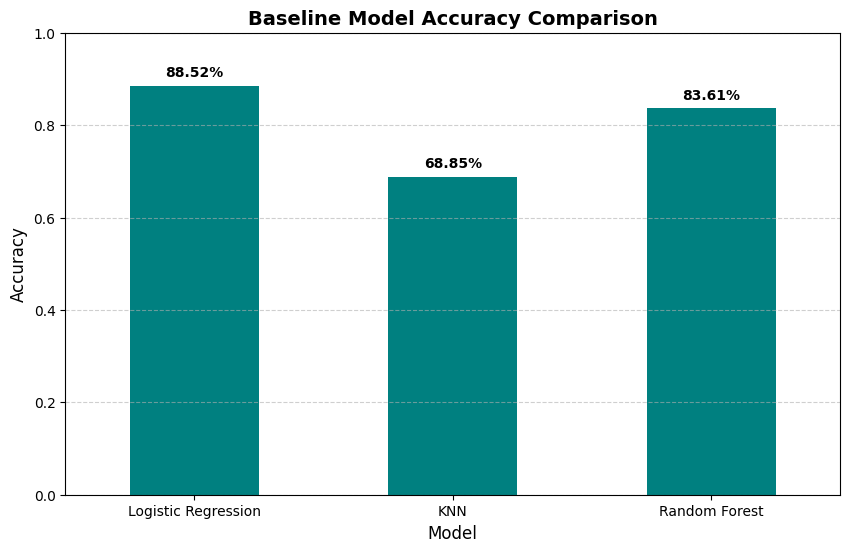

In [21]:
# Visualize model accuracy comparison
model_compare = pd.DataFrame(model_scores, index=["accuracy"])
ax = model_compare.T.plot.bar(figsize=(10, 6), color="teal", legend=False)

plt.title("Baseline Model Accuracy Comparison", fontsize=14, fontweight="bold")
plt.xlabel("Model", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.xticks(rotation=0)
plt.ylim(0, 1.0)
plt.grid(axis="y", linestyle="--", alpha=0.6)

# Annotate accuracy values on top of bars
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2%}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.02), ha="center", fontweight="bold")

os.makedirs("plots", exist_ok=True)
plt.savefig("plots/06_model_comparison.png", bbox_inches="tight")
plt.show()

## 6. Hyperparameter Tuning

Baseline accuracy scores:
- **Logistic Regression**: ~88.5%
- **Random Forest**: ~83.6%
- **KNN**: ~68.9%

We will tune:
1. **KNN** by hand across `n_neighbors` (1 to 20)
2. **LogisticRegression** and **RandomForestClassifier** using `RandomizedSearchCV`
3. Fine-tune our top model using `GridSearchCV`

In [22]:
# 1. Tune KNN by hand
train_scores = []
test_scores = []

# Test n_neighbors from 1 to 20
neighbors = range(1, 21)
knn = KNeighborsClassifier()

for i in neighbors:
    knn.set_params(n_neighbors=i)
    knn.fit(X_train, y_train)
    train_scores.append(knn.score(X_train, y_train))
    test_scores.append(knn.score(X_test, y_test))

print(f"Maximum KNN test accuracy: {max(test_scores):.2%}")

Maximum KNN test accuracy: 75.41%


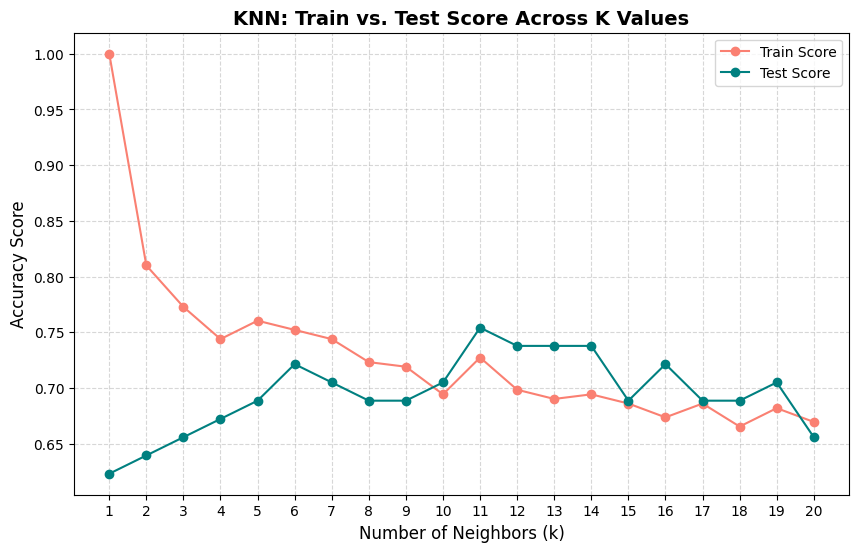

In [23]:
# Plot KNN train vs test scores
plt.figure(figsize=(10, 6))
plt.plot(neighbors, train_scores, label="Train Score", color="salmon", marker="o")
plt.plot(neighbors, test_scores, label="Test Score", color="teal", marker="o")
plt.xticks(np.arange(1, 21, 1))
plt.xlabel("Number of Neighbors (k)", fontsize=12)
plt.ylabel("Accuracy Score", fontsize=12)
plt.title("KNN: Train vs. Test Score Across K Values", fontsize=14, fontweight="bold")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

os.makedirs("plots", exist_ok=True)
plt.savefig("plots/07_knn_tuning.png", bbox_inches="tight")
plt.show()

### Hyperparameter Tuning with `RandomizedSearchCV`

Even after tuning `n_neighbors`, KNN maxes out around ~75% test accuracy, still lagging significantly behind Logistic Regression (88.5%) and Random Forest (83.6%). We will set KNN aside and tune the top two models using `RandomizedSearchCV`.

In [24]:
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV

# Hyperparameter grid for LogisticRegression
log_reg_grid = {
    "C": np.logspace(-4, 4, 20),
    "solver": ["liblinear"]
}

# Hyperparameter grid for RandomForestClassifier
rf_grid = {
    "n_estimators": np.arange(10, 1000, 50),
    "max_depth": [None, 3, 5, 10],
    "min_samples_split": np.arange(2, 20, 2),
    "min_samples_leaf": np.arange(1, 20, 2)
}

In [25]:
# Tune LogisticRegression using RandomizedSearchCV
np.random.seed(42)

rs_log_reg = RandomizedSearchCV(
    LogisticRegression(),
    param_distributions=log_reg_grid,
    cv=5,
    n_iter=20,
    verbose=True,
    random_state=42
)

rs_log_reg.fit(X_train, y_train)

print("Best Logistic Regression parameters:", rs_log_reg.best_params_)
print(f"Logistic Regression test score: {rs_log_reg.score(X_test, y_test):.2%}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Logistic Regression parameters: {'solver': 'liblinear', 'C': np.float64(0.23357214690901212)}
Logistic Regression test score: 88.52%


In [26]:
# Tune RandomForestClassifier using RandomizedSearchCV
np.random.seed(42)

rs_rf = RandomizedSearchCV(
    RandomForestClassifier(),
    param_distributions=rf_grid,
    cv=5,
    n_iter=20,
    verbose=True,
    random_state=42
)

rs_rf.fit(X_train, y_train)

print("Best Random Forest parameters:", rs_rf.best_params_)
print(f"Random Forest test score: {rs_rf.score(X_test, y_test):.2%}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Random Forest parameters: {'n_estimators': np.int64(210), 'min_samples_split': np.int64(4), 'min_samples_leaf': np.int64(19), 'max_depth': 3}
Random Forest test score: 86.89%


### Fine-Tuning with `GridSearchCV`

Since `LogisticRegression` delivers the highest score and fastest convergence, we can use `GridSearchCV` to perform an exhaustive search across our focused parameter grid.

In [27]:
# Fine-tune LogisticRegression using GridSearchCV
log_reg_grid = {
    "C": np.logspace(-4, 4, 30),
    "solver": ["liblinear"]
}

gs_log_reg = GridSearchCV(
    LogisticRegression(),
    param_grid=log_reg_grid,
    cv=5,
    verbose=True
)

gs_log_reg.fit(X_train, y_train)

print("Best GridSearchCV parameters:", gs_log_reg.best_params_)
print(f"GridSearchCV test score: {gs_log_reg.score(X_test, y_test):.2%}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best GridSearchCV parameters: {'C': np.float64(0.20433597178569418), 'solver': 'liblinear'}
GridSearchCV test score: 88.52%


## 7. Evaluating Our Tuned Machine Learning Classifier (Beyond Accuracy)

In medical diagnostics, false negatives (classifying a sick patient as healthy) can be fatal. Hence, we must evaluate our tuned classifier across multiple metrics:
- **ROC Curve & AUC Score**
- **Confusion Matrix**
- **Classification Report** (Precision, Recall, F1-Score)
- **Cross-Validated Metrics** (using 5-fold cross validation)

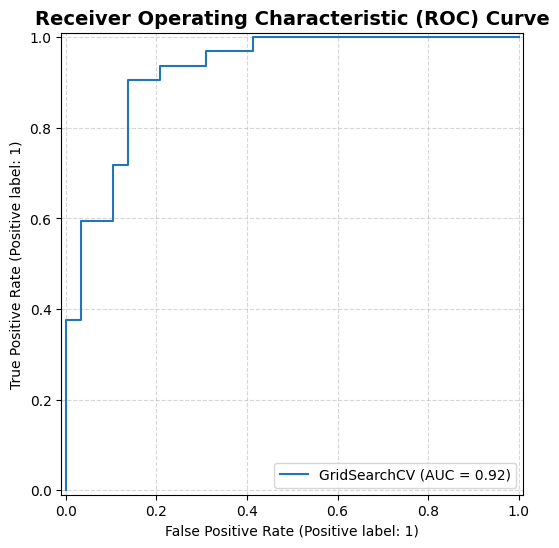

In [28]:
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay, classification_report, confusion_matrix

# Generate predictions with our tuned model
y_preds = gs_log_reg.predict(X_test)

# Plot ROC curve and calculate AUC metric
fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(gs_log_reg, X_test, y_test, ax=ax)
plt.title("Receiver Operating Characteristic (ROC) Curve", fontsize=14, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
os.makedirs("plots", exist_ok=True)
plt.savefig("plots/08_roc_curve.png", bbox_inches="tight")
plt.show()

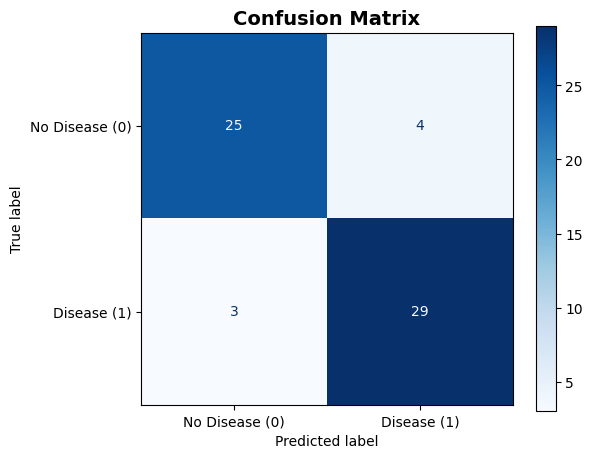

In [29]:
# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(
    gs_log_reg,
    X_test,
    y_test,
    cmap="Blues",
    display_labels=["No Disease (0)", "Disease (1)"],
    ax=ax
)
plt.title("Confusion Matrix", fontsize=14, fontweight="bold")
os.makedirs("plots", exist_ok=True)
plt.savefig("plots/09_confusion_matrix.png", bbox_inches="tight")
plt.show()

In [30]:
# Classification Report (single test split)
print("=== Classification Report (Single Test Set) ===\n")
print(classification_report(y_test, y_preds, target_names=["No Disease", "Disease"]))

=== Classification Report (Single Test Set) ===

              precision    recall  f1-score   support

  No Disease       0.89      0.86      0.88        29
     Disease       0.88      0.91      0.89        32

    accuracy                           0.89        61
   macro avg       0.89      0.88      0.88        61
weighted avg       0.89      0.89      0.89        61



### Calculate Evaluation Metrics Using Cross-Validation (`cross_val_score`)

To ensure our evaluation is robust and not just lucky on one test split, we compute Accuracy, Precision, Recall, and F1 across 5 folds.

In [31]:
from sklearn.model_selection import cross_val_score

# Instantiate best model with tuned parameters
best_params = gs_log_reg.best_params_
clf = LogisticRegression(**best_params)

# Cross-validated accuracy
cv_acc = np.mean(cross_val_score(clf, X, y, cv=5, scoring="accuracy"))

# Cross-validated precision
cv_precision = np.mean(cross_val_score(clf, X, y, cv=5, scoring="precision"))

# Cross-validated recall
cv_recall = np.mean(cross_val_score(clf, X, y, cv=5, scoring="recall"))

# Cross-validated F1-score
cv_f1 = np.mean(cross_val_score(clf, X, y, cv=5, scoring="f1"))

print(f"Cross-Validated Accuracy:  {cv_acc:.2%}")
print(f"Cross-Validated Precision: {cv_precision:.2%}")
print(f"Cross-Validated Recall:    {cv_recall:.2%}")
print(f"Cross-Validated F1-Score:  {cv_f1:.2%}")

Cross-Validated Accuracy:  84.47%
Cross-Validated Precision: 82.08%
Cross-Validated Recall:    92.12%
Cross-Validated F1-Score:  86.73%


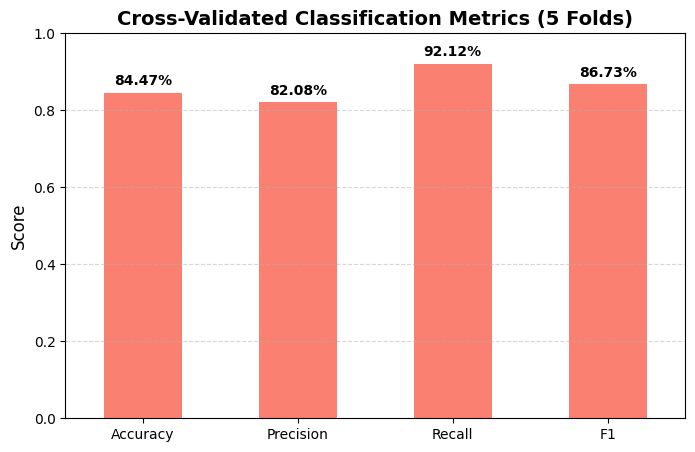

In [32]:
# Visualize Cross-Validated Metrics
cv_metrics = pd.DataFrame({
    "Accuracy": cv_acc,
    "Precision": cv_precision,
    "Recall": cv_recall,
    "F1": cv_f1
}, index=[0])

ax = cv_metrics.T.plot.bar(figsize=(8, 5), legend=False, color="salmon")
plt.title("Cross-Validated Classification Metrics (5 Folds)", fontsize=14, fontweight="bold")
plt.ylabel("Score", fontsize=12)
plt.ylim(0, 1.0)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.2%}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.02), ha="center", fontweight="bold")

os.makedirs("plots", exist_ok=True)
plt.savefig("plots/10_cv_metrics.png", bbox_inches="tight")
plt.show()

## 8. Feature Importance

Feature importance asks: **"Which features contributed most to the model's predictions, and in which direction?"**

For `LogisticRegression`, we can inspect the model's `coef_` attribute. Each coefficient represents the change in log-odds of having heart disease (`target=1`) for a one-unit change in that feature.

In [33]:
# Fit model with best parameters
clf = LogisticRegression(**gs_log_reg.best_params_)
clf.fit(X_train, y_train)

# Display feature coefficients
print("Model coefficients:", clf.coef_)

Model coefficients: [[ 0.00320769 -0.86062049  0.66001432 -0.01155971 -0.00166496  0.04017236
   0.31603405  0.02458922 -0.60470171 -0.56795456  0.45085392 -0.63733328
  -0.67555094]]


In [34]:
# Match feature names to their coefficient values
feature_dict = dict(zip(X.columns, list(clf.coef_[0])))
feature_dict

{'age': np.float64(0.0032076883508599633),
 'sex': np.float64(-0.8606204883695241),
 'cp': np.float64(0.660014324982524),
 'trestbps': np.float64(-0.01155970600550047),
 'chol': np.float64(-0.0016649614843449207),
 'fbs': np.float64(0.040172360271308105),
 'restecg': np.float64(0.31603405294617176),
 'thalach': np.float64(0.02458922341328129),
 'exang': np.float64(-0.604701713592625),
 'oldpeak': np.float64(-0.5679545646616215),
 'slope': np.float64(0.4508539209693025),
 'ca': np.float64(-0.6373332766360461),
 'thal': np.float64(-0.6755509369619848)}

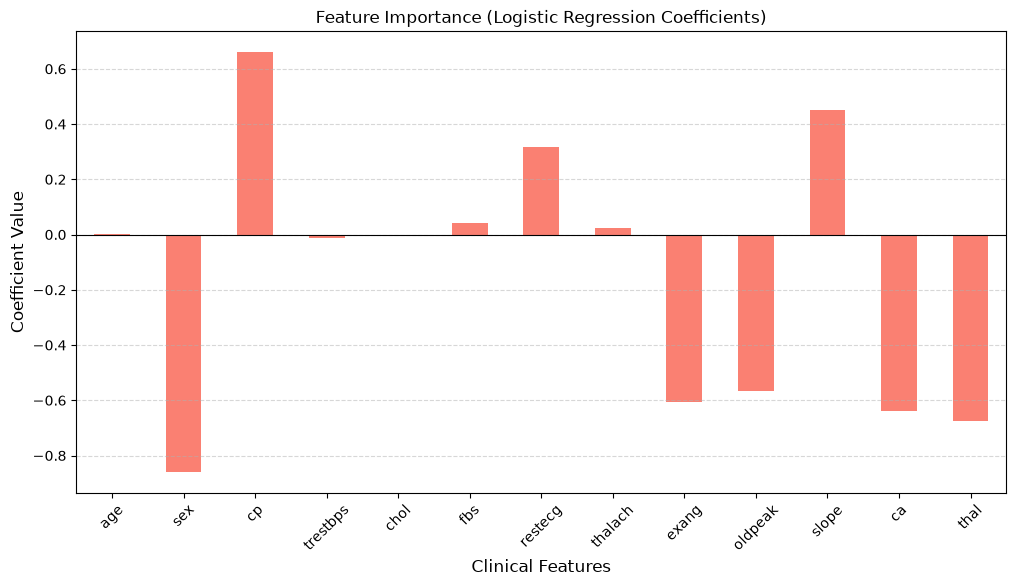

In [35]:
# Visualize Feature Importance
feature_df = pd.DataFrame(feature_dict, index=[0])
os.makedirs("plots", exist_ok=True)

fig, ax = plt.subplots(figsize=(12, 6))
colors = ["salmon" if val >= 0 else "lightblue" for val in feature_df.values[0]]
feature_df.T.plot.bar(title="Feature Importance (Logistic Regression Coefficients)", legend=False, color=colors, ax=ax)

plt.xlabel("Clinical Features", fontsize=12)
plt.ylabel("Coefficient Value", fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Add zero line
plt.axhline(0, color="black", linewidth=0.8, linestyle="-")

plt.savefig("plots/11_feature_importance.png", bbox_inches="tight")
plt.show()

### Feature Importance Interpretation

- **Positive Coefficients (Red / Salmon)**: Higher values correlate with a **higher probability of heart disease**.
  - `cp` (chest pain type): As chest pain type increases (from typical angina to atypical/non-anginal), heart disease risk increases significantly.
  - `slope` (slope of peak exercise ST segment): Higher slope values increase likelihood of disease.
- **Negative Coefficients (Blue / Lightblue)**: Higher values correlate with a **lower probability of heart disease**.
  - `sex`: `sex=1` (male) correlates with a lower ratio of positive cases compared to `sex=0` (female) in this dataset.
  - `ca` (number of major vessels colored by flourosopy): More vessels showing clear blood flow corresponds to lower risk of disease.

## 9. Next Steps & Experimentation

If we want to push model performance even further:
1. **More Data**: Collect additional patient samples to improve generalization.
2. **Advanced Ensembles**: Test CatBoost, XGBoost, or LightGBM.
3. **Model Deployment**: Export the model using `joblib` or `pickle` for inference in a production web API.